In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
df = pd.read_csv("week3_data.csv")
print("First 5 rows:")
display(df.head())
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:")
display(df.describe())

First 5 rows:


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


Dataset shape: (32, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB

Missing values:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Duplicate rows: 1

Statistical summary:


,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.437500,103.500000,128.500000,304.680000
std,70.039591,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000


In [10]:
print("Rows before removing duplicates:", len(df))
df = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(df))

Rows before removing duplicates: 32
Rows after removing duplicates: 31


In [11]:
df["Date"] = df["Date"].astype("string").str.strip()
df["Date"] = df["Date"].str.strip("'\"")
df["Date"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    errors="coerce"
)
missing_date = df["Date"].isna()
df.loc[missing_date, "Date"] = pd.Timestamp("2020-12-22")
print(df[["Date"]].head(10))
print("\nMissing dates:", df["Date"].isna().sum())

        Date
0 2020-12-01
1 2020-12-02
2 2020-12-03
3 2020-12-04
4 2020-12-05
5 2020-12-06
6 2020-12-07
7 2020-12-08
8 2020-12-09
9 2020-12-10

Missing dates: 0


In [12]:
print("Missing Calories before cleaning:",
      df["Calories"].isna().sum())
calories_median = df["Calories"].median()
df["Calories"] = df["Calories"].fillna(calories_median)
print("Missing Calories after cleaning:",
      df["Calories"].isna().sum())
print("Median Calories used:", calories_median)

Missing Calories before cleaning: 2
Missing Calories after cleaning: 0
Median Calories used: 300.0


In [13]:
df["Unusual_Duration"] = df["Duration"] > 120
df["Pulse_Check"] = df["Maxpulse"] < df["Pulse"]
print("Unusual duration records:")
display(df[df["Unusual_Duration"]])
print("Pulse records requiring verification:")
display(df[df["Pulse_Check"]])

Unusual duration records:


,Duration,Date,Pulse,Maxpulse,Calories,Unusual_Duration,Pulse_Check
7,450,2020-12-08,104,134,253.3,True,False


Pulse records requiring verification:


,Duration,Date,Pulse,Maxpulse,Calories,Unusual_Duration,Pulse_Check
23,60,2020-12-23,130,101,300.0,False,True


In [14]:
df["Calories_Per_Minute"] = (
    df["Calories"] / df["Duration"].replace(0, np.nan)
)
df["Duration_Category"] = pd.cut(
    df["Duration"],
    bins=[0, 30, 60, 120, float("inf")],
    labels=["Short", "Medium", "Long", "Very Long"],
    right=True
)
df["Exercise_Month"] = df["Date"].dt.month_name()
display(df.head(10))

,Duration,Date,Pulse,Maxpulse,Calories,Unusual_Duration,Pulse_Check,Calories_Per_Minute,Duration_Category,Exercise_Month
0,60,2020-12-01,110,130,409.1,False,False,6.818333,Medium,December
1,60,2020-12-02,117,145,479.0,False,False,7.983333,Medium,December
2,60,2020-12-03,103,135,340.0,False,False,5.666667,Medium,December
3,45,2020-12-04,109,175,282.4,False,False,6.275556,Medium,December
4,45,2020-12-05,117,148,406.0,False,False,9.022222,Medium,December
5,60,2020-12-06,102,127,300.0,False,False,5.000000,Medium,December
6,60,2020-12-07,110,136,374.0,False,False,6.233333,Medium,December
7,450,2020-12-08,104,134,253.3,True,False,0.562889,Very Long,December
8,30,2020-12-09,109,133,195.1,False,False,6.503333,Short,December
9,60,2020-12-10,98,124,269.0,False,False,4.483333,Medium,December


In [15]:
filtered_df = df[
    (df["Duration"] <= 120) &
    (~df["Pulse_Check"])
].copy()

print("Original dataset rows:", 32)
print("Rows after duplicate removal:", len(df))
print("Rows selected for analysis:", len(filtered_df))

display(filtered_df.head(10))

Original dataset rows: 32
Rows after duplicate removal: 31
Rows selected for analysis: 29


,Duration,Date,Pulse,Maxpulse,Calories,Unusual_Duration,Pulse_Check,Calories_Per_Minute,Duration_Category,Exercise_Month
0,60,2020-12-01,110,130,409.1,False,False,6.818333,Medium,December
1,60,2020-12-02,117,145,479.0,False,False,7.983333,Medium,December
2,60,2020-12-03,103,135,340.0,False,False,5.666667,Medium,December
3,45,2020-12-04,109,175,282.4,False,False,6.275556,Medium,December
4,45,2020-12-05,117,148,406.0,False,False,9.022222,Medium,December
5,60,2020-12-06,102,127,300.0,False,False,5.000000,Medium,December
6,60,2020-12-07,110,136,374.0,False,False,6.233333,Medium,December
8,30,2020-12-09,109,133,195.1,False,False,6.503333,Short,December
9,60,2020-12-10,98,124,269.0,False,False,4.483333,Medium,December
10,60,2020-12-11,103,147,329.3,False,False,5.488333,Medium,December


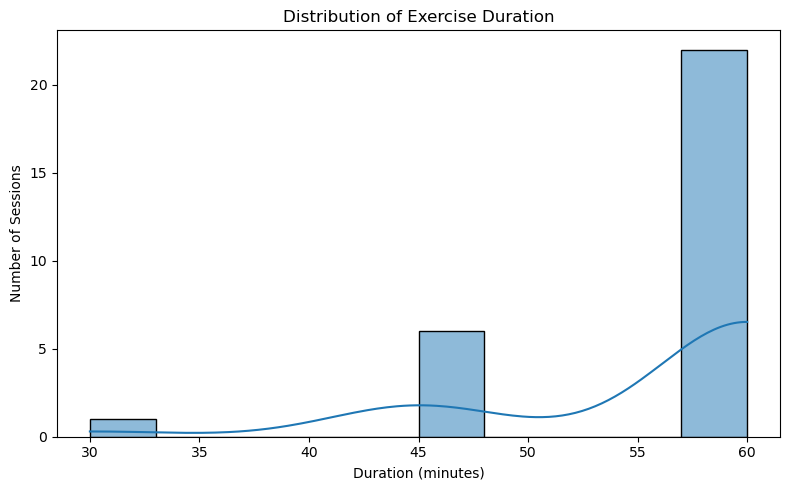

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=filtered_df,
    x="Duration",
    bins=10,
    kde=True
)
plt.title("Distribution of Exercise Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

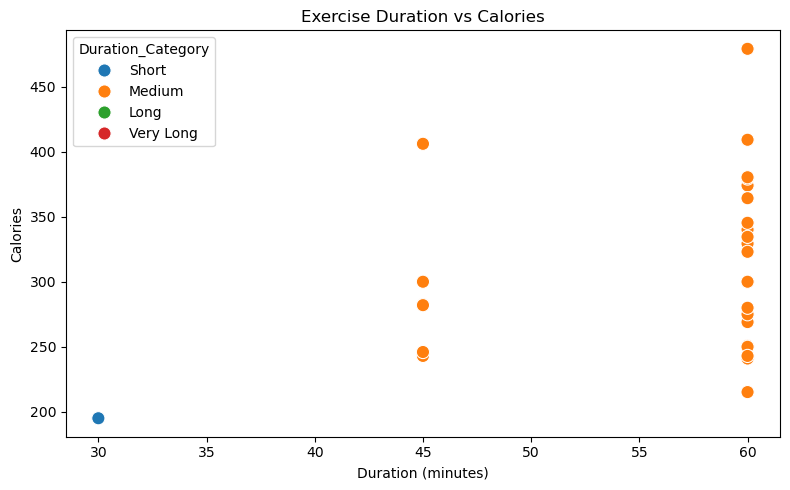

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=filtered_df,
    x="Duration",
    y="Calories",
    hue="Duration_Category",
    s=90
)

plt.title("Exercise Duration vs Calories")
plt.xlabel("Duration (minutes)")
plt.ylabel("Calories")
plt.tight_layout()
plt.show()

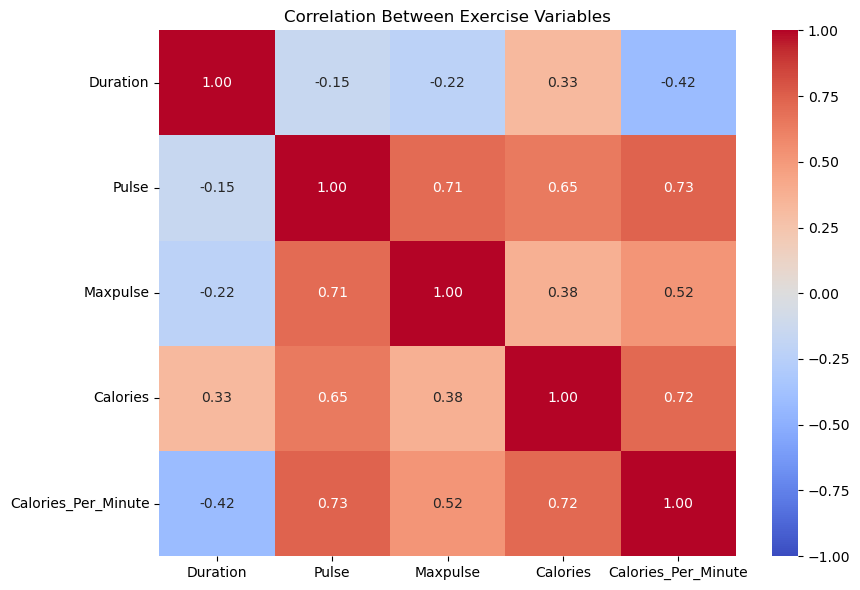

In [18]:
numeric_cols = [
    "Duration",
    "Pulse",
    "Maxpulse",
    "Calories",
    "Calories_Per_Minute"
]
plt.figure(figsize=(9, 6))
sns.heatmap(
    filtered_df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Exercise Variables")
plt.tight_layout()
plt.show()

In [19]:
print("Final dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDate data type:", df["Date"].dtype)
print("\nFinal dataset preview:")
display(df.head(10))

Final dataset shape: (31, 10)

Missing values:
Duration               0
Date                   0
Pulse                  0
Maxpulse               0
Calories               0
Unusual_Duration       0
Pulse_Check            0
Calories_Per_Minute    0
Duration_Category      0
Exercise_Month         0
dtype: int64

Duplicate rows: 0

Date data type: datetime64[ns]

Final dataset preview:


,Duration,Date,Pulse,Maxpulse,Calories,Unusual_Duration,Pulse_Check,Calories_Per_Minute,Duration_Category,Exercise_Month
0,60,2020-12-01,110,130,409.1,False,False,6.818333,Medium,December
1,60,2020-12-02,117,145,479.0,False,False,7.983333,Medium,December
2,60,2020-12-03,103,135,340.0,False,False,5.666667,Medium,December
3,45,2020-12-04,109,175,282.4,False,False,6.275556,Medium,December
4,45,2020-12-05,117,148,406.0,False,False,9.022222,Medium,December
5,60,2020-12-06,102,127,300.0,False,False,5.000000,Medium,December
6,60,2020-12-07,110,136,374.0,False,False,6.233333,Medium,December
7,450,2020-12-08,104,134,253.3,True,False,0.562889,Very Long,December
8,30,2020-12-09,109,133,195.1,False,False,6.503333,Short,December
9,60,2020-12-10,98,124,269.0,False,False,4.483333,Medium,December


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "cleaned_week3_data.csv", index=False)
filtered_df.to_csv(output_dir / "filtered_week3_data.csv", index=False)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!
